In [1]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'

# =========================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'

color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'

line_width = 1.5


fc = FileChooser('Señales AC3E/Femenino')
fc.layout = widgets.Layout(width='auto')
display(fc)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales AC3E\Femenino', filename='', title='', show_…

In [3]:
archivo = Path(fc.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)
fs_r = 8000

señal_MBK  = datos[:, 0] - np.mean(datos[:, 0])

b,a = sig.butter(4,65, 'hp', fs=fs_r)
señal_MBK = sig.filtfilt(b,a,señal_MBK)

señal_ACC  = -datos[:, 1]
señal_ACC  = señal_ACC - np.mean(señal_ACC)
señal_ACC = sig.filtfilt(b,a,señal_ACC) 

if max(abs(señal_ACC)) > 0:
    señal_ACC = señal_ACC / max(abs(señal_ACC)) 
#señal_ACC = sig.filtfilt(b,a,señal_ACC)

señal_EGG  = datos[:, 3]
señal_dEGG = np.gradient(señal_EGG)
señal_OVV  = datos[:, 2] - np.mean(datos[:, 2])
if max(abs(señal_OVV)) > 0:
    señal_OVV = señal_OVV / max(abs(señal_OVV)) 
if max(señal_dEGG) > 0:
    señal_dEGG = señal_dEGG / max(señal_dEGG) 

to = 0
tf = 50
tiempos = np.arange(to, tf, 1000/fs_r)


# ==============================================================================================================================================================
SP = CONMF.NNMF_GIF(speech=señal_MBK,
                acelerometro=señal_ACC,
                dEGG = señal_dEGG,
                tiempos=tiempos,
                fs=fs_r,
                norma='frobenius',
                pre_iteraciones=0,
                iteraciones=251,
                p_filtro=12,
                alfa=0.96,
                beta_speech=0.55,
                beta_acc= 0.55,
                pre_enfasis_speech=True,
                pre_enfasis_acc=True,
                duracion=5.5,
                guardar_proceso=True,
                normalizar_espectrogramas=True,
                ventana = 'boxcar'
)

SP.flujo1_speech = sig.filtfilt(b,a,SP.flujo1_speech)
SP.flujo2_speech = sig.filtfilt(b,a,SP.flujo2_speech)
SP.flujo1_acc = sig.filtfilt(b,a,SP.flujo1_acc)
SP.flujo2_acc = sig.filtfilt(b,a,SP.flujo2_acc)

<>:126: SyntaxWarning: invalid escape sequence '\h'
<>:126: SyntaxWarning: invalid escape sequence '\h'
C:\Users\Emiliano\AppData\Local\Temp\ipykernel_16900\4095705598.py:126: SyntaxWarning: invalid escape sequence '\h'
  '''


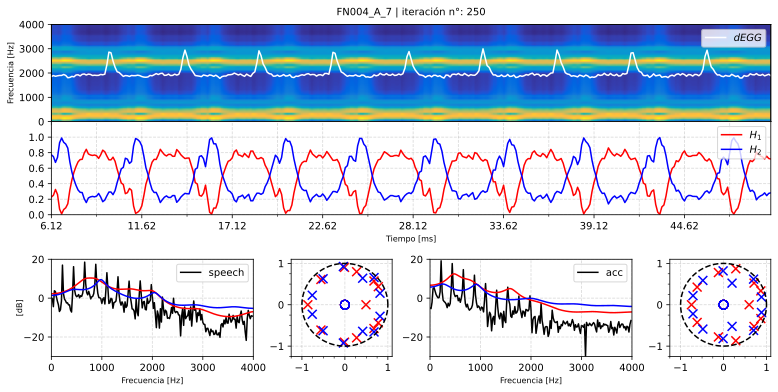

In [4]:
fig = plt.figure(figsize=(10,6))
widths  = [1,0.5,1,0.5]
heights = [1,0.5,1]
gs  = fig.add_gridspec(3, 4,width_ratios=widths,height_ratios=heights,left=0,right=1,wspace=0.25,hspace=0.55)

# Señales temporales
ax1 = fig.add_subplot(gs[0,:])
ax1_ = ax1.twinx()
ax2 = fig.add_subplot(gs[1,:],sharex=ax1)
pos1 = ax1.get_position()
pos2 = ax2.get_position()

# nueva altura para que "toque" al de arriba
new_height = pos1.y0 - pos2.y0

ax2.set_position([pos2.x0, pos2.y0, pos2.width, new_height])

ax3 = fig.add_subplot(gs[2,0])
ax4 = fig.add_subplot(gs[2,1])
ax5 = fig.add_subplot(gs[2,2])
ax6 = fig.add_subplot(gs[2,3])
''' 
ax7 = fig.add_subplot(gs[3,0:2])
ax7_ = ax7.twinx()
ax8 = fig.add_subplot(gs[3,2:])
ax8_ = ax8.twinx()
ax9 = fig.add_subplot(gs[4,0:2])
ax9_ = ax9.twinx()
ax10 = fig.add_subplot(gs[4,2:])
ax10_ = ax10.twinx()
''' 

#axes = [ax1,ax1_,ax2,ax3, ax4,ax5,ax6,ax7,ax7_,ax8,ax8_,ax9,ax9_,ax10,ax10_]
axes = [ax1,ax1_,ax2,ax3, ax4,ax5,ax6]
fontsize = 8
for i in range(0,251):
        for a in axes:
                a.clear()
        #========================= Espectrograma aproximado sincronizado
        ax1.imshow(SP.proceso_espectrograma_aprox_plot[i],
                        cmap=cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado,
                                SP.fo_espectrograma, SP.ff_espectrograma])
        ax1.set_ylabel('Frecuencia [Hz]',fontsize=fontsize)
        #ax1.set_xlabel("Tiempo [ms]")

        # ------------- dEGG
        ax1_.tick_params(labelbottom=False)
        ax1_.plot(SP.tiempos_espectrograma_sincronizado,SP.dEGG_sincronizado,color='white', label=r"$dEGG$", linewidth=line_width)
        ax1_.legend(loc=legend_loc)
        ax1_.set_xlim(SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado)
        ax1_.set_ylim([-2, 2])
        #ax1_.set_xticks(np.arange(SP.to_espectrograma_sincronizado, SP.tf_espectrograma_sincronizado, SP.duracion_ventana))
        ax1_.set_yticks([])
        ax1.tick_params(labelbottom=False)
        #========================= Funciones de activación
        ax2.plot(SP.tiempos_espectrograma_sincronizado,SP.proceso_H1[i],color=color1,label=r'$H_1$')
        ax2.plot(SP.tiempos_espectrograma_sincronizado,SP.proceso_H2[i],color=color2,label=r'$H_2$')
        ax2.set_yticks(np.arange(0.0,1.1,0.2))
        ax2.set_ylim([0,1.2])
        ax2.set_xlim(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado)
        ax2.set_xticks(np.arange(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado,SP.duracion_ventana))
        ax2.set_xticks(np.arange(SP.to_espectrograma_sincronizado,SP.tf_espectrograma_sincronizado,SP.duracion_ventana/2),minor=True)
        ax2.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax2.legend(loc=legend_loc)
        ax2.set_xlabel('Tiempo [ms]',fontsize=fontsize)
        #========================= Respuesta en frecuencia/polos-ceros speech
        # ------------- Respuesta en frecuencia
        theta = np.linspace(0, 2*np.pi, 200)
        fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
        fw1,hw1 = sig.freqz([1],SP.proceso_a_W1_speech[i],fs=fs_r)
        fw2,hw2 = sig.freqz([1],SP.proceso_a_W2_speech[i],fs=fs_r)
        ax3.plot(fw1, 10*np.log10(np.abs(hw1)), color=color1)
        ax3.plot(fw2, 10*np.log10(np.abs(hw2)), color=color2)
        ax3.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
        ax3.set_xlim(0,fs_r/2)
        ax3.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        ax3.set_xlabel('Frecuencia [Hz]',fontsize=fontsize)
        ax3.set_ylabel('[dB]',labelpad=-0.5,fontsize=fontsize)
        ax3.set_ylim([-30,20])
        ax3.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax4.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        #ax4.yaxis.tick_right()
        #ax4.yaxis.set_label_position("right")
        ax4.scatter(np.real(SP.proceso_ceros_W1_speech[i]), np.imag(SP.proceso_ceros_W1_speech[i]),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax4.scatter(np.real(SP.proceso_polos_W1_speech[i]), np.imag(SP.proceso_polos_W1_speech[i]),s=80, marker='x', color=color1, label='Polos')
        ax4.scatter(np.real(SP.proceso_ceros_W2_speech[i]), np.imag(SP.proceso_ceros_W2_speech[i]),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax4.scatter(np.real(SP.proceso_polos_W2_speech[i]), np.imag(SP.proceso_polos_W2_speech[i]),s=80, marker='x', color=color2, label='Polos')
        ax4.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax4.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        #ax4.set_ylabel(r"$Im\{z\}$",labelpad=-0.5)
        #ax4.set_xlabel(r"$Re\{z\}$")
        ax4.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        #========================= Respuesta en frecuencia/polos-ceros ACC
        # ------------- Respuesta en frecuencia
        fftseñal, fseñal = Funciones.FFT(señal_ACC, fs_r)
        fw1,hw1 = sig.freqz([1],SP.proceso_a_W1_acc[i],fs=fs_r)
        fw2,hw2 = sig.freqz([1],SP.proceso_a_W2_acc[i],fs=fs_r)
        ax5.plot(fw1, 10*np.log10(np.abs(hw1)), color=color1)
        ax5.plot(fw2, 10*np.log10(np.abs(hw2)), color=color2)
        ax5.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='acc', color=color3, zorder=-1)
        ax5.set_xlim(0,fs_r/2)
        ax5.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        ax5.set_xlabel('Frecuencia [Hz]',fontsize=fontsize)
        #ax5.set_ylabel('[dB]',labelpad=-0.5)
        ax5.set_ylim([-30,20])
        ax5.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax6.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        #ax6.yaxis.tick_right()
        #ax6.yaxis.set_label_position("right")
        ax6.scatter(np.real(SP.proceso_ceros_W1_acc[i]), np.imag(SP.proceso_ceros_W1_acc[i]),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax6.scatter(np.real(SP.proceso_polos_W1_acc[i]), np.imag(SP.proceso_polos_W1_acc[i]),s=80, marker='x', color=color1, label='Polos')
        ax6.scatter(np.real(SP.proceso_ceros_W2_acc[i]), np.imag(SP.proceso_ceros_W2_acc[i]),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax6.scatter(np.real(SP.proceso_polos_W2_acc[i]), np.imag(SP.proceso_polos_W2_acc[i]),s=80, marker='x', color=color2, label='Polos')
        ax6.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax6.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        #ax6.set_ylabel(r"$Im\{z\}$",labelpad=-0.5)
        #ax6.set_xlabel(r"$Re\{z\}$")
        ax6.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        #ax6.legend(loc='upper right')

        ''' 
        # --- SPEECH ---
        pos3 = ax3.get_position()
        pos4 = ax4.get_position()

        x_center_speech = (pos3.x0 + pos4.x1) / 2
        y_top_speech = pos3.y1 + 0.01

        fig.text(x_center_speech, y_top_speech, 'Resultados - Speech',
                ha='center', va='bottom', fontsize=12,bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))

        # --- ACC ---
        pos5 = ax5.get_position()
        pos6 = ax6.get_position()

        x_center_acc = (pos5.x0 + pos6.x1) / 2
        y_top_acc = pos5.y1+0.01

        fig.text(x_center_acc, y_top_acc, 'Resultados - ACC',
                ha='center', va='bottom', fontsize=12,bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))


        #========================= Flujos speech
        ax7.plot(SP.tiempos_gve,SP.proceso_flujo1_speech[i],color=color1,label=r'$\hat{u}_{g1}(t)$ - speech')
        ax7_.set_yticks([])
        ax7_.plot(SP.tiempos_gve,SP.proceso_flujo2_speech[i],color=color2,label=r'$\hat{u}_{g2}(t)$ - speech')
        ax7.set_xlim([to,tf])
        ax7.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax7.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax7.set_xlabel('Tiempo [ms]',fontsize=fontsize)
        #========================= Flujos ACC
        ax8.plot(SP.tiempos_gve,SP.proceso_flujo1_acc[i],color=color1,label=r'$\hat{u}_{g1}(t)$ - acc')
        ax8_.set_yticks([])
        ax8_.plot(SP.tiempos_gve,SP.proceso_flujo2_acc[i],color=color2,label=r'$\hat{u}_{g2}(t)$ - acc')
        ax8_.set_xlim([to,tf])
        ax8.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax8.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax8.set_xlabel('Tiempo [ms]',fontsize=fontsize)   
        #========================= Funciones glóticas speech
        ax9.plot(SP.tiempos_gve,SP.proceso_dflujo1_speech[i],color=color1,label=r'$\hat{v}_{g1}(t)$ - speech')
        ax9_.set_yticks([])
        ax9_.plot(SP.tiempos_gve,SP.proceso_dflujo2_speech[i],color=color2,label=r'$\hat{v}_{g2}(t)$ - speech')
        ax9.set_xlim([to,tf])
        ax9.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax9.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax9.set_xlabel('Tiempo [ms]',fontsize=fontsize)
        #========================= Funciones glóticas ACC
        ax10.plot(SP.tiempos_gve,SP.proceso_dflujo1_acc[i],color=color1,label=r'$\hat{v}_{g1}(t)$ - acc');
        ax10_.set_yticks([])
        ax10_.plot(SP.tiempos_gve,SP.proceso_dflujo2_acc[i],color=color2,label=r'$\hat{v}_{g2}(t)$ - acc');
        ax10.set_xlim([to,tf])
        ax10.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax10.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax10.set_xlabel('Tiempo [ms]',fontsize=fontsize);
        '''
        fig.suptitle(
        f"{nombre_archivo.removesuffix(".txt")} | iteración n°: {i}",
        fontsize=10,
        y=0.92
        );
        fig.savefig("Animacion CONMF/"+nombre_archivo+"_"+str(i)+'.pdf',bbox_inches = 'tight');


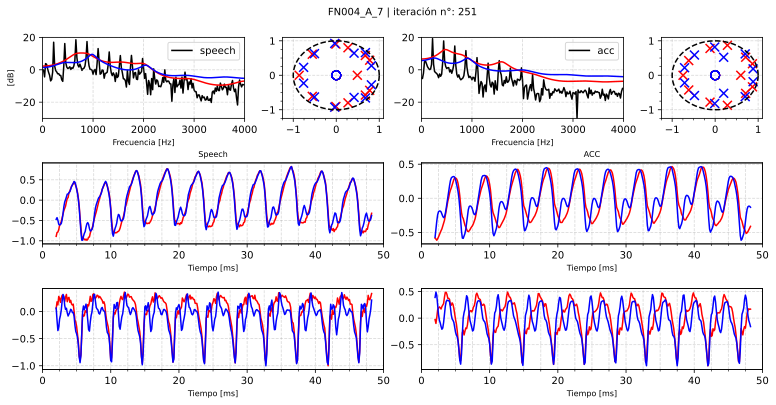

In [5]:
fig = plt.figure(figsize=(10,6))
widths  = [1,0.5,1,0.5]
heights = [1,1,1]
gs  = fig.add_gridspec(3, 4,width_ratios=widths,height_ratios=heights,left=0,right=1,wspace=0.25,hspace=0.55)

# Señales temporales
ax1 = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
ax3 = fig.add_subplot(gs[0,2])
ax4 = fig.add_subplot(gs[0,3])

ax5 = fig.add_subplot(gs[1,0:2])
ax5_ = ax5.twinx()
ax6 = fig.add_subplot(gs[1,2:])
ax6_ = ax6.twinx()

ax7 = fig.add_subplot(gs[2,0:2])
ax7_ = ax7.twinx()
ax8 = fig.add_subplot(gs[2,2:])
ax8_ = ax8.twinx()

axes = [ax1,ax1,ax2,ax3,ax4,ax5,ax5_,ax6,ax6_,ax7,ax7_,ax8,ax8_]
fontsize = 8
for i in range(0,251):
        #i = 1
        for a in axes:
                a.clear()

        #========================= Respuesta en frecuencia/polos-ceros speech
        # ------------- Respuesta en frecuencia
        theta = np.linspace(0, 2*np.pi, 200)
        fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
        fw1,hw1 = sig.freqz([1],SP.proceso_a_W1_speech[i],fs=fs_r)
        fw2,hw2 = sig.freqz([1],SP.proceso_a_W2_speech[i],fs=fs_r)
        ax1.plot(fw1, 10*np.log10(np.abs(hw1)), color=color1)
        ax1.plot(fw2, 10*np.log10(np.abs(hw2)), color=color2)
        ax1.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='speech', color=color3, zorder=-1)
        ax1.set_xlim(0,fs_r/2)
        ax1.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        ax1.set_xlabel('Frecuencia [Hz]',fontsize=fontsize)
        ax1.set_ylabel('[dB]',labelpad=-0.5,fontsize=fontsize)
        ax1.set_ylim([-30,20])
        ax1.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax2.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        #ax4.yaxis.tick_right()
        #ax4.yaxis.set_label_position("right")
        ax2.scatter(np.real(SP.proceso_ceros_W1_speech[i]), np.imag(SP.proceso_ceros_W1_speech[i]),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax2.scatter(np.real(SP.proceso_polos_W1_speech[i]), np.imag(SP.proceso_polos_W1_speech[i]),s=80, marker='x', color=color1, label='Polos')
        ax2.scatter(np.real(SP.proceso_ceros_W2_speech[i]), np.imag(SP.proceso_ceros_W2_speech[i]),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax2.scatter(np.real(SP.proceso_polos_W2_speech[i]), np.imag(SP.proceso_polos_W2_speech[i]),s=80, marker='x', color=color2, label='Polos')
        ax2.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax2.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        #ax4.set_ylabel(r"$Im\{z\}$",labelpad=-0.5)
        #ax4.set_xlabel(r"$Re\{z\}$")
        ax2.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        #========================= Respuesta en frecuencia/polos-ceros ACC
        # ------------- Respuesta en frecuencia
        fftseñal, fseñal = Funciones.FFT(señal_ACC, fs_r)
        fw1,hw1 = sig.freqz([1],SP.proceso_a_W1_acc[i],fs=fs_r)
        fw2,hw2 = sig.freqz([1],SP.proceso_a_W2_acc[i],fs=fs_r)
        ax3.plot(fw1, 10*np.log10(np.abs(hw1)), color=color1)
        ax3.plot(fw2, 10*np.log10(np.abs(hw2)), color=color2)
        ax3.plot(fseñal, 10*np.log10(np.abs(fftseñal)), label='acc', color=color3, zorder=-1)
        ax3.set_xlim(0,fs_r/2)
        ax3.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        ax3.set_xlabel('Frecuencia [Hz]',fontsize=fontsize)
        #ax5.set_ylabel('[dB]',labelpad=-0.5)
        ax3.set_ylim([-30,20])
        ax3.legend(loc='upper right')
        # ------------- Polos y ceros   
        ax4.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        #ax6.yaxis.tick_right()
        #ax6.yaxis.set_label_position("right")
        ax4.scatter(np.real(SP.proceso_ceros_W1_acc[i]), np.imag(SP.proceso_ceros_W1_acc[i]),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax4.scatter(np.real(SP.proceso_polos_W1_acc[i]), np.imag(SP.proceso_polos_W1_acc[i]),s=80, marker='x', color=color1, label='Polos')
        ax4.scatter(np.real(SP.proceso_ceros_W2_acc[i]), np.imag(SP.proceso_ceros_W2_acc[i]),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax4.scatter(np.real(SP.proceso_polos_W2_acc[i]), np.imag(SP.proceso_polos_W2_acc[i]),s=80, marker='x', color=color2, label='Polos')
        ax4.set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax4.set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        #ax6.set_ylabel(r"$Im\{z\}$",labelpad=-0.5)
        #ax6.set_xlabel(r"$Re\{z\}$")
        ax4.grid(True, linestyle='dashed', color='gray', alpha=0.3)
        #ax6.legend(loc='upper right')

        #========================= Flujos speech
        ax5.plot(SP.tiempos_gve,SP.proceso_flujo1_speech[i],color=color1,label=r'$\hat{u}_{g1}(t)$ - speech')
        ax5_.set_yticks([])
        ax5_.plot(SP.tiempos_gve,SP.proceso_flujo2_speech[i],color=color2,label=r'$\hat{u}_{g2}(t)$ - speech')
        ax5.set_xlim([to,tf])
        ax5.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax5.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax5.set_xlabel('Tiempo [ms]',fontsize=fontsize)
        ax5.set_title('Speech',fontsize=fontsize)
        #========================= Flujos ACC
        ax6.plot(SP.tiempos_gve,SP.proceso_flujo1_acc[i],color=color1,label=r'$\hat{u}_{g1}(t)$ - acc')
        ax6_.set_yticks([])
        ax6_.plot(SP.tiempos_gve,SP.proceso_flujo2_acc[i],color=color2,label=r'$\hat{u}_{g2}(t)$ - acc')
        ax6_.set_xlim([to,tf])
        ax6.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax6.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax6.set_xlabel('Tiempo [ms]',fontsize=fontsize)
        ax6.set_title('ACC',fontsize=fontsize)   
        #========================= Funciones glóticas speech
        ax7.plot(SP.tiempos_gve,SP.proceso_dflujo1_speech[i],color=color1,label=r'$\hat{v}_{g1}(t)$ - speech')
        ax7_.set_yticks([])
        ax7_.plot(SP.tiempos_gve,SP.proceso_dflujo2_speech[i],color=color2,label=r'$\hat{v}_{g2}(t)$ - speech')
        ax7.set_xlim([to,tf])
        ax7.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax7.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax7.set_xlabel('Tiempo [ms]',fontsize=fontsize)
        #========================= Funciones glóticas ACC
        ax8.plot(SP.tiempos_gve,SP.proceso_dflujo1_acc[i],color=color1,label=r'$\hat{v}_{g1}(t)$ - acc');
        ax8_.set_yticks([])
        ax8_.plot(SP.tiempos_gve,SP.proceso_dflujo2_acc[i],color=color2,label=r'$\hat{v}_{g2}(t)$ - acc');
        ax8.set_xlim([to,tf])
        ax8.set_xticks(np.arange(to,tf,2.5),minor=True)
        ax8.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax8.set_xlabel('Tiempo [ms]',fontsize=fontsize);

        fig.suptitle(
        f"{nombre_archivo.removesuffix(".txt")} | iteración n°: {i+1}",
        fontsize=10,
        y=0.95
        );
        fig.savefig("Animacion CONMF/"+nombre_archivo+"_flujos_"+str(i)+'.pdf',bbox_inches = 'tight');